# Streaming Decision Tree Demo

This notebook shows the `numcompute_stream` package learning from a data stream:

1. **Load** a CSV in chunks with the custom I/O pipeline (`io.py`).
2. **Summarise** the stream incrementally (`stats.py`).
3. **Train** a pipeline (imputer → scaler → decision tree) chunk by chunk with `.partial_fit()`, using **test-then-train** evaluation (`stream.py`).
4. **Visualise** accuracy, AUC, timing and memory over time (`visualise.py`).
5. **Compare** trees with different `buffer_size` values.

**Dataset:** `data/sensor_stream.csv` holds 6,000 synthetic machine readings (five sensors and a `fault` label). About 3% of sensor values are missing (`NA`), and the fault rule changes at row 4,000 (concept drift). It is created by `generate_stream_data.py`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Make the repository root importable when the notebook runs from demo/.
ROOT = Path.cwd().parent if Path.cwd().name == "demo" else Path.cwd()
sys.path.insert(0, str(ROOT))

from numcompute_stream.io import iter_csv_chunks
from numcompute_stream.stats import StreamingSummary
from numcompute_stream.preprocessing import SimpleImputer, StandardScaler
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.visualise import (
    plot_metric_over_time, compare_models,
    plot_predictions_vs_ground_truth, plot_confusion_matrix,
)

DATA = ROOT / "demo" / "data" / "sensor_stream.csv"
FEATURES = ["temperature", "vibration", "pressure", "humidity", "load"]
CHUNK_SIZE = 200
np.set_printoptions(precision=3, suppress=True)
%matplotlib inline

## 1. Load the CSV as a stream

`iter_csv_chunks` reads the file lazily and yields one NumPy array of `CHUNK_SIZE` rows at a time, so the whole file is never held in memory. `NA` cells become `NaN`. The last column is the label.

In [2]:
def stream_chunks(chunk_size=CHUNK_SIZE):
    """Yield (X_chunk, y_chunk) pairs straight from the CSV file."""
    for chunk in iter_csv_chunks(DATA, chunk_size=chunk_size, skip_header=1):
        yield chunk[:, :5], chunk[:, 5].astype(int)

X0, y0 = next(stream_chunks())
print("first chunk:", X0.shape, "labels:", y0.shape)
print("missing values per feature:", {f: int(n) for f, n in zip(FEATURES, np.isnan(X0).sum(axis=0))})
print("first 3 rows:\n", X0[:3])

first chunk: (200, 5) labels: (200,)
missing values per feature: {'temperature': 9, 'vibration': 3, 'pressure': 8, 'humidity': 4, 'load': 7}
first 3 rows:
 [[ 72.438   2.962 107.032  78.722   0.895]
 [ 61.68    4.574 109.203  79.643   0.46 ]
 [ 76.004   1.017 122.425  67.622   0.34 ]]


## 2. Streaming statistics

`StreamingSummary.update_stats(X_chunk)` merges each chunk into running per-column statistics (count, mean, variance, min, max and P² quantile estimates) without storing earlier chunks. Missing values are skipped.

rows seen: 6000
feature       count     mean     std      min   median      max
temperature    5795    69.88    8.03    34.89    70.04    97.63
vibration      5802     3.00    2.14     0.02     2.48    22.23
pressure       5826   100.45   14.95    44.50   100.46   153.35
humidity       5826    50.34   17.32    20.00    50.47    80.00
load           5859     0.60    0.15    -0.04     0.60     1.21


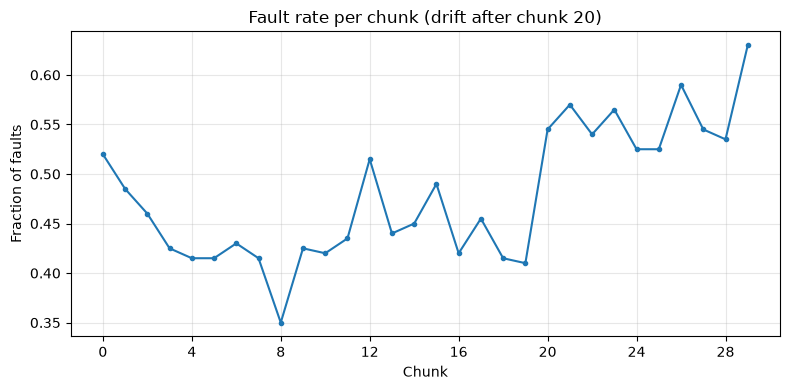

In [3]:
summary = StreamingSummary(quantiles=(0.25, 0.5, 0.75))
fault_rate = []
for X_chunk, y_chunk in stream_chunks():
    summary.update_stats(X_chunk)
    fault_rate.append(y_chunk.mean())

stats = summary.result()
print(f"rows seen: {summary.n_rows_}")
print(f"{'feature':<12}{'count':>7}{'mean':>9}{'std':>8}{'min':>9}{'median':>9}{'max':>9}")
for j, name in enumerate(FEATURES):
    print(f"{name:<12}{stats['count'][j]:>7}{stats['mean'][j]:>9.2f}{stats['std'][j]:>8.2f}"
          f"{stats['min'][j]:>9.2f}{stats['quantiles'][1, j]:>9.2f}{stats['max'][j]:>9.2f}")

plot_metric_over_time(fault_rate, title="Fault rate per chunk (drift after chunk 20)",
                      ylabel="Fraction of faults");

## 3. Train a streaming pipeline

The pipeline fills missing values with a running mean, standardises features with running Welford statistics, and feeds a depth-limited decision tree. The tree **buffers** incoming chunks and retrains from scratch once `buffer_size` samples have arrived.

`StreamTrainer.process_chunk` uses **test-then-train**: each chunk is first predicted by the current model (so every score is on unseen data) and then used for training. Chunks that arrive before the first retrain are only trained on.

In [4]:
pipe = Pipeline([
    ("impute", SimpleImputer(strategy="mean")),
    ("scale", StandardScaler()),
    ("tree", DecisionTreeClassifier(max_depth=6, buffer_size=600, random_state=0)),
])

trainer = StreamTrainer(pipe, rolling_window=600, auc_pos_label=1, verbose=True)
history = trainer.run(stream_chunks())

chunk    0 | n=  200 | acc=   -   | cum=   -   | fit=   0.40ms mem=   14.6KB


chunk    1 | n=  200 | acc=   -   | cum=   -   | fit=   0.34ms mem=   24.2KB


chunk    2 | n=  200 | acc=   -   | cum=   -   | fit=  54.41ms mem=   27.2KB retrained


chunk    3 | n=  200 | acc= 84.0% | cum= 84.0% | fit=   0.20ms mem=   36.9KB


chunk    4 | n=  200 | acc= 76.0% | cum= 80.0% | fit=   0.24ms mem=   46.5KB


chunk    5 | n=  200 | acc= 81.0% | cum= 80.3% | fit=  18.60ms mem=   26.2KB retrained


... (20 outputs left out)

chunk   26 | n=  200 | acc= 77.0% | cum= 80.4% | fit=  16.71ms mem=   24.7KB retrained


chunk   27 | n=  200 | acc= 81.0% | cum= 80.4% | fit=   0.20ms mem=   34.3KB


chunk   28 | n=  200 | acc= 78.0% | cum= 80.3% | fit=   0.27ms mem=   43.9KB


chunk   29 | n=  200 | acc= 80.5% | cum= 80.3% | fit=  19.35ms mem=   28.2KB retrained


In [5]:
for key, value in trainer.summary().items():
    print(f"{key:>15}: {value:.4f}" if isinstance(value, float) else f"{key:>15}: {value}")

tree = pipe.named_steps["tree"]
root = tree.root_
print(f"\nfinal tree: depth {tree.get_depth()}, {tree.get_n_leaves()} leaves, "
      f"{tree.n_retrains_} retrains")
print(f"root split: {FEATURES[root.feature]} <= {root.threshold:.3f} (standardised units)")

       n_chunks: 30
      n_samples: 6000
       n_scored: 5400
       accuracy: 0.8030
       f1_macro: 0.8021
            auc: 0.8126
 total_fit_time: 0.2230

final tree: depth 6, 44 leaves, 10 retrains
root split: load <= -0.013 (standardised units)


## 4. Metrics over time

Dashed lines mark the chunks where the tree retrained. Cumulative accuracy is smooth; rolling accuracy (last 600 scored samples) reacts faster, for example to the drift after chunk 20.

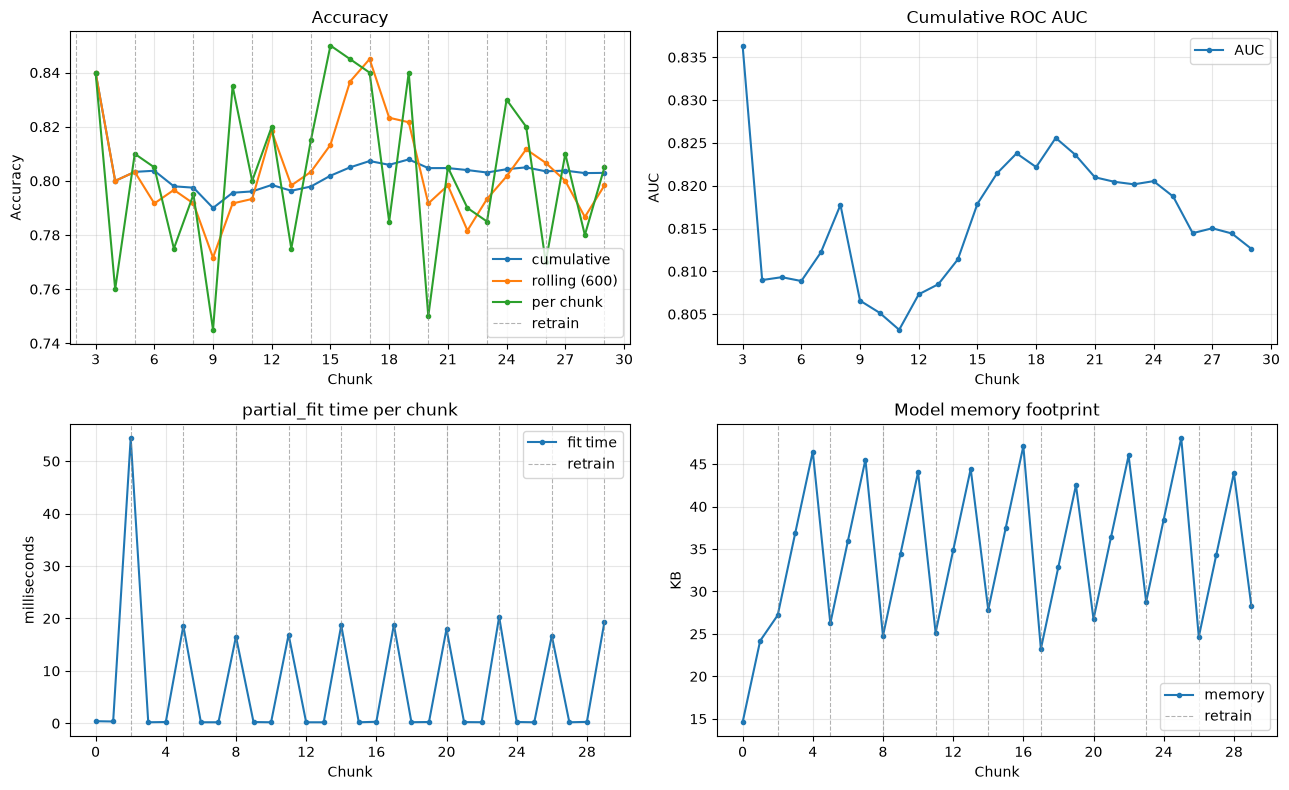

In [6]:
retrains = np.flatnonzero(trainer.get_metric("retrained") == 1)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
plot_metric_over_time(
    {"cumulative": trainer.get_metric("cumulative_accuracy"),
     "rolling (600)": trainer.get_metric("rolling_accuracy"),
     "per chunk": trainer.get_metric("chunk_accuracy")},
    title="Accuracy", ylabel="Accuracy", marks=retrains, ax=axes[0, 0])
plot_metric_over_time(trainer.get_metric("cumulative_auc"), title="Cumulative ROC AUC",
                      ylabel="AUC", label="AUC", ax=axes[0, 1])
plot_metric_over_time(trainer.get_metric("fit_time") * 1000, title="partial_fit time per chunk",
                      ylabel="milliseconds", label="fit time", marks=retrains, ax=axes[1, 0])
plot_metric_over_time(trainer.get_metric("model_bytes") / 1024, title="Model memory footprint",
                      ylabel="KB", label="memory", marks=retrains, ax=axes[1, 1])
fig.tight_layout()
fig.savefig(ROOT / "demo" / "stream_metrics.png", dpi=120)

Fit time spikes on retrain chunks (the tree is rebuilt) and is tiny otherwise (the chunk is only buffered). Memory grows as the buffer fills and is released after each retrain.

## 5. Predictions on the latest chunk

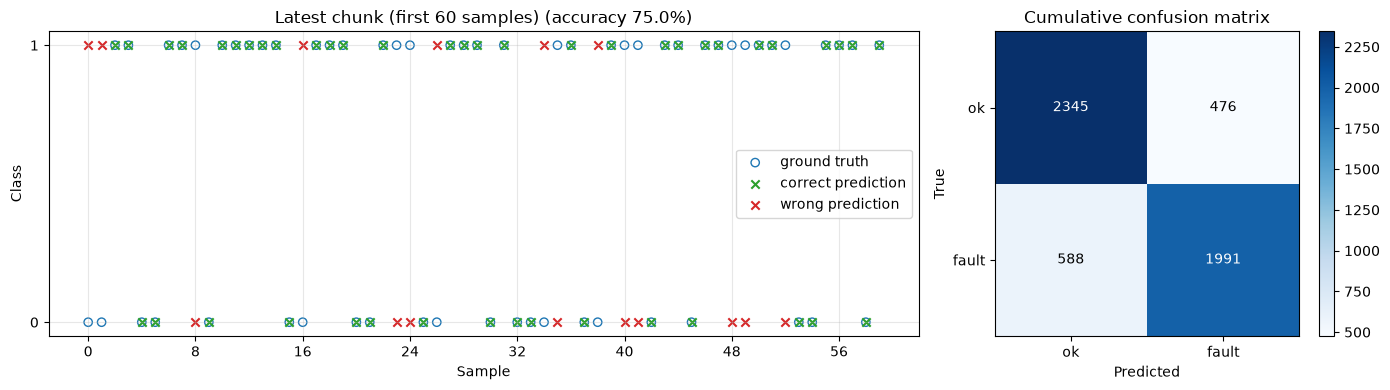

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
plot_predictions_vs_ground_truth(trainer.last_y_true_[:60], trainer.last_y_pred_[:60],
                                 title="Latest chunk (first 60 samples)", ax=axes[0])
matrix, labels = trainer.confusion_matrix()
plot_confusion_matrix(matrix, ["ok", "fault"], title="Cumulative confusion matrix", ax=axes[1])
fig.tight_layout()

## 6. Comparing buffer sizes

A small buffer retrains often on little data; a large buffer trains better trees but reacts slowly and cannot predict until it first fills. Each model sees the same stream.

In [8]:
def run_stream(buffer_size):
    model = Pipeline([
        ("impute", SimpleImputer(strategy="mean")),
        ("scale", StandardScaler()),
        ("tree", DecisionTreeClassifier(max_depth=6, buffer_size=buffer_size, random_state=0)),
    ])
    trainer = StreamTrainer(model, rolling_window=600)
    trainer.run(stream_chunks())
    return trainer

results = {size: run_stream(size) for size in (200, 600, 2000)}
print(f"{'buffer':>7}{'accuracy':>10}{'scored':>8}{'retrains':>10}{'total fit (ms)':>16}")
for size, t in results.items():
    s = t.summary()
    print(f"{size:>7}{s['accuracy']:>10.3f}{s['n_scored']:>8}"
          f"{int(np.nansum(t.get_metric('retrained'))):>10}{s['total_fit_time'] * 1000:>16.1f}")

 buffer  accuracy  scored  retrains  total fit (ms)
    200     0.791    5800        30           288.6
    600     0.803    5400        10           185.1
   2000     0.821    4000         3            98.2


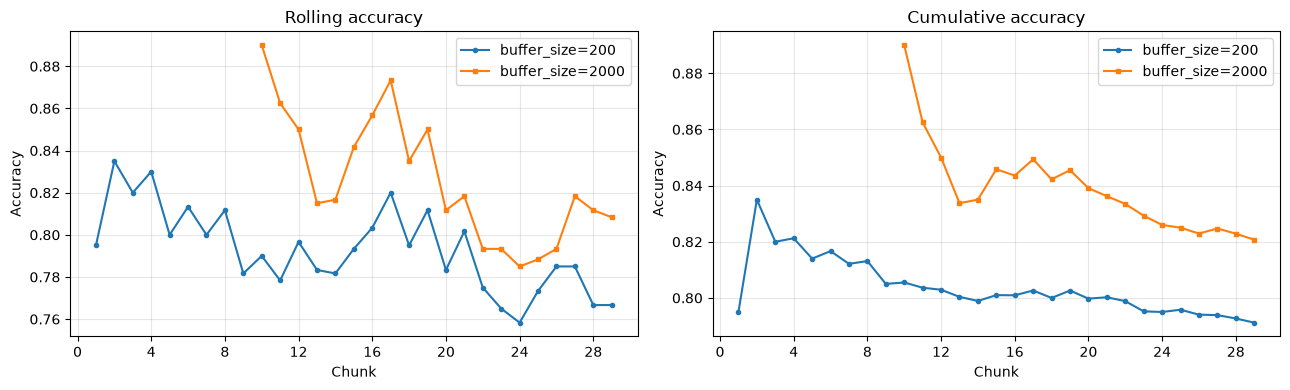

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
compare_models(results[200].get_metric("rolling_accuracy"),
               results[2000].get_metric("rolling_accuracy"),
               labels=["buffer_size=200", "buffer_size=2000"],
               title="Rolling accuracy", ylabel="Accuracy", ax=axes[0])
compare_models(results[200].get_metric("cumulative_accuracy"),
               results[2000].get_metric("cumulative_accuracy"),
               labels=["buffer_size=200", "buffer_size=2000"],
               title="Cumulative accuracy", ylabel="Accuracy", ax=axes[1])
fig.tight_layout()

## Summary

- The whole workflow is streaming: the CSV is read in chunks, statistics and preprocessing update incrementally, and the tree retrains from a bounded buffer.
- Test-then-train evaluation scores every chunk before learning from it.
- `buffer_size` trades accuracy per tree against how often (and how quickly) the model adapts. The full benchmark (`python -m benchmark.run_stream_benchmarks`) measures this trade-off on larger streams with and without drift.